# Airbnb Madrid: Listing Features and Nightly Prices

## Business question

**What can a property owner learn from comparable Madrid listings when reviewing nightly prices and property improvements?**

The case study starts with a client's request to optimize nightly prices. It explores the Madrid market, defines a comparable group of listings, and examines how amenities, review scores, host characteristics, and booking conditions relate to price.

## Analysis at a glance

- **Data:** five listing-level Parquet tables joined on `id`.
- **Study group:** entire-home apartments with one to three bedrooms, a kitchen, and a listed nightly price no higher than €200.
- **Methods:** descriptive statistics, distributions, group medians, and Spearman correlations.
- **Main findings in the saved analysis:** amenity groups and Superhost status show price differences; review scores and host response measures show weak relationships with price.

## Reading guide

1. Data sources and preparation
2. Madrid market context
3. Study scope and filters
4. Analytical questions
5. Comparisons by listing characteristic
6. Conclusions
7. Data limitations

The [project README](README.md) links to the source brief and explains how to inspect the analysis.

## 1. Data sources and preparation

The project uses five listing-level Parquet files, joined on the listing identifier `id`.

### Source table fields

The source tables contain information about hosts, listing locations, property features, rental conditions, and guest reviews. Source field names are retained.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [2]:
# Load the data
conditions_df = pd.read_parquet('data/raw data/airbnb_madrid_conditions.parquet')
host_df = pd.read_parquet('data/raw data/airbnb_madrid_host.parquet')
location_df = pd.read_parquet('data/raw data/airbnb_madrid_location.parquet')
property_df = pd.read_parquet('data/raw data/airbnb_madrid_property.parquet')
reviews_df = pd.read_parquet('data/raw data/airbnb_madrid_reviews.parquet')

In [3]:
# What is the shape of the data?
conditions_df.shape, host_df.shape, location_df.shape, property_df.shape, reviews_df.shape

((21020, 7), (21020, 13), (21020, 7), (21020, 13), (21020, 16))

### Join the source tables

Combine rental conditions, host, location, property, and review information using the listing identifier. The following cells inspect the size and structure of the merged data.

In [4]:
# Merge the dataframes on the listing identifier `id`
df = conditions_df.merge(host_df, on='id').merge(location_df, on='id').merge(property_df, on='id').merge(reviews_df, on='id')

## 2. Madrid market context

### Dataset size and structure

In [5]:
# How large is the market?
df.shape

(21020, 52)

In [6]:
# What do the data look like? 
df.head()

,id,price,minimum_nights,maximum_nights,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,host_response_time,host_response_rate,host_is_superhost,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,reviews_per_month,days_since_last_review,days_since_first_review,number_of_reviews_en,number_of_reviews_es,number_of_reviews_otros
0,0,70.0,1,365,flexible,0,0,within_an_hour,100.0,1,...,10.0,10.0,9.0,10.0,0.61,28,3589,65.0,5.0,3.0
1,1,17.0,4,40,strict_14_with_grace_period,0,0,NaN,NaN,0,...,10.0,10.0,8.0,9.0,0.52,544,1918,17.0,12.0,4.0
2,2,50.0,15,730,moderate,0,0,within_an_hour,100.0,0,...,NaN,NaN,NaN,NaN,NaN,-1,-1,NaN,NaN,NaN
3,3,80.0,5,730,moderate,0,0,within_a_few_hours,100.0,0,...,10.0,10.0,10.0,10.0,0.14,7,1868,6.0,2.0,1.0
4,4,115.0,3,10,moderate,0,0,within_an_hour,100.0,1,...,10.0,10.0,10.0,10.0,0.64,33,3144,37.0,23.0,7.0


In [7]:
# What are the variable data types?
df.dtypes

id                                    int64
price                               float64
minimum_nights                        int64
maximum_nights                        int64
cancellation_policy                     str
require_guest_profile_picture         int64
require_guest_phone_verification      int64
host_response_time                      str
host_response_rate                  float64
host_is_superhost                     int64
host_has_profile_pic                  int64
host_identity_verified                int64
host_verifications_email              int64
host_verifications_phone              int64
host_verifications_reviews            int64
host_verifications_facebook           int64
host_verifications_government_id      int64
calculated_host_listings_count        int64
host_seniority                        int64
neighbourhood                           str
neighbourhood_group                     str
latitude                            float64
longitude                       

### Nightly price distribution

count    21020.000000
mean       131.326213
std        364.802634
min          1.000000
25%         40.000000
50%         65.000000
75%        102.000000
max       9999.000000
Name: price, dtype: float64


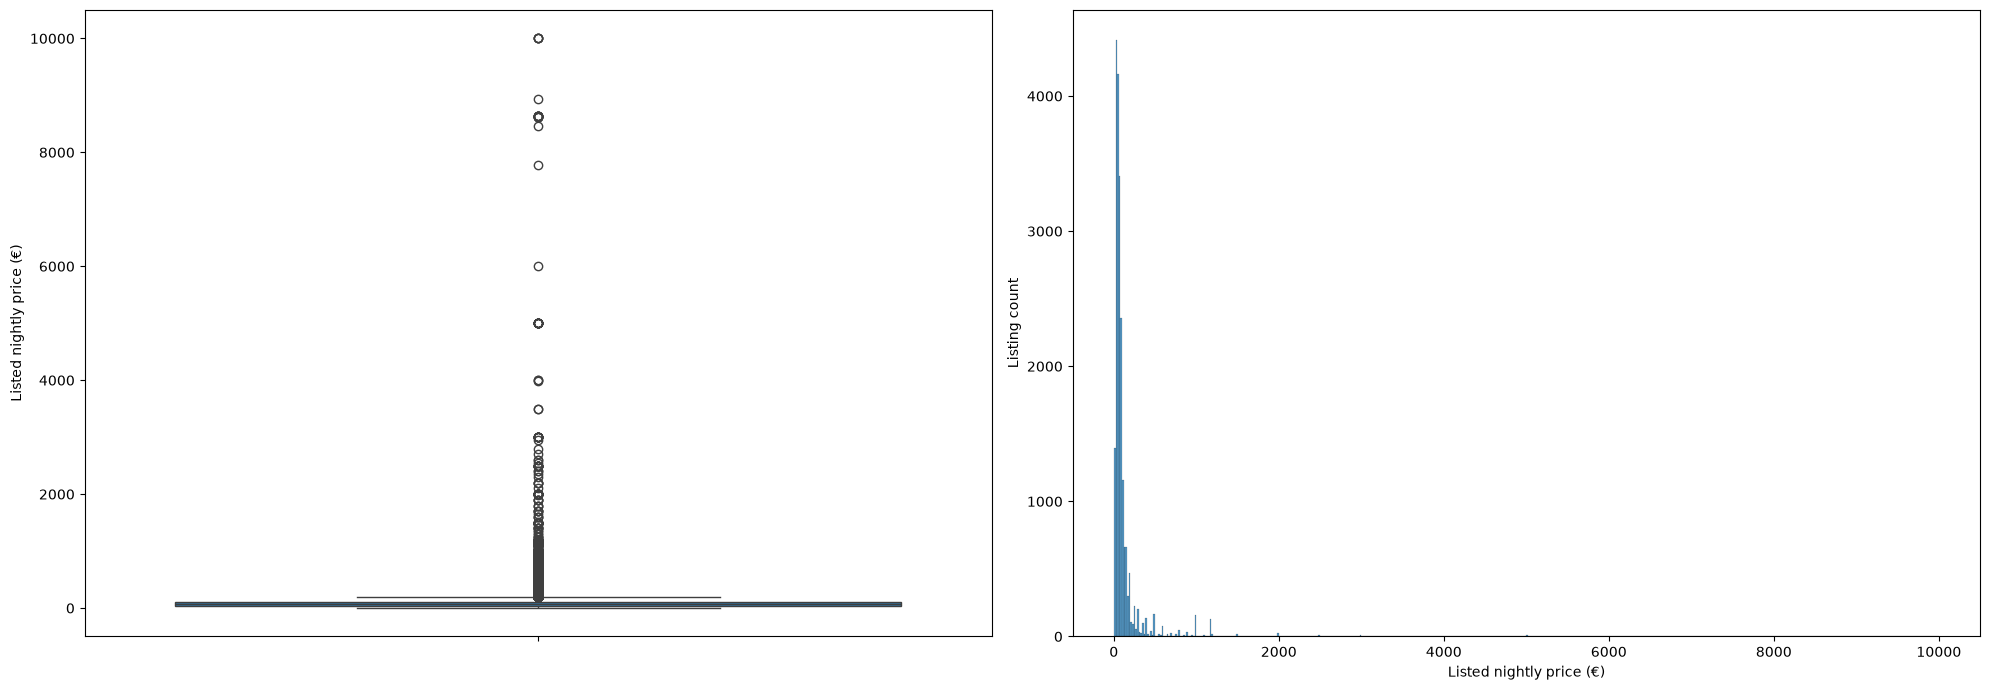

In [8]:
# What do prices look like across Madrid?
print(df.price.describe())

fig, ax = plt.subplots(1,2, figsize=(20, 7) )
sns.boxplot(data=df, y='price', ax=ax[0])
sns.histplot(data=df, x='price', binwidth=20)
ax[0].set_ylabel('Listed nightly price (€)')
ax[1].set_xlabel('Listed nightly price (€)')
ax[1].set_ylabel('Listing count')
plt.tight_layout()


Some listed prices reach €9,999 per night and may distort the analysis. The original project applies a business-rule filter that retains properties priced at up to €200 per night.

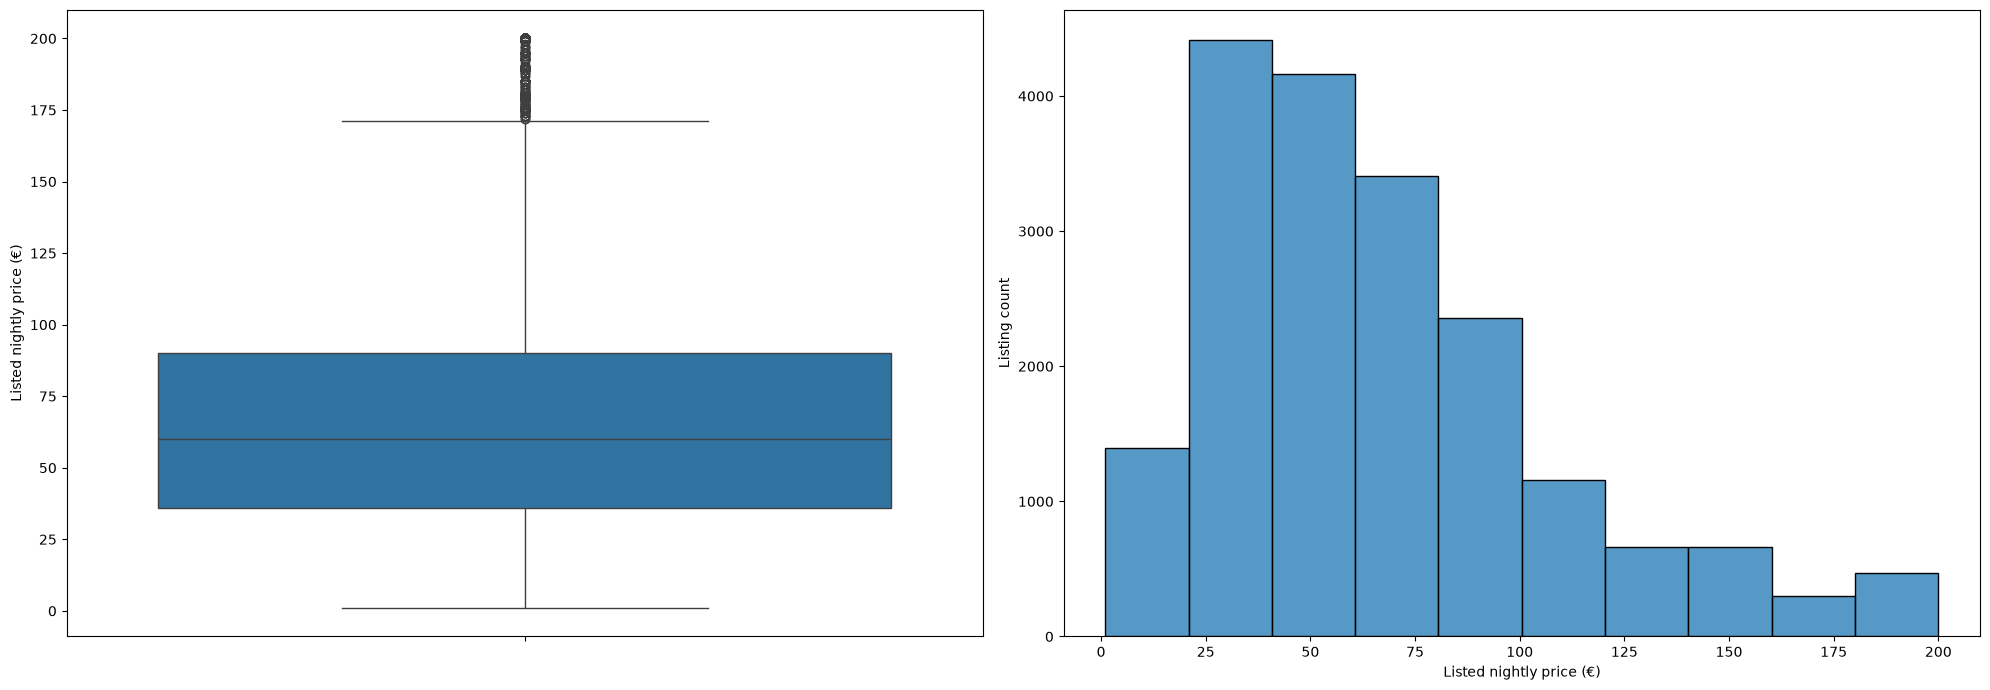

In [9]:
df_clean = df[df['price'] <= 200]

# Review the charts again
fig, ax = plt.subplots(1,2, figsize=(20, 7) )
sns.boxplot(data=df_clean, y='price', ax=ax[0])
sns.histplot(data=df_clean, x='price', binwidth=20)
ax[0].set_ylabel('Listed nightly price (€)')
ax[1].set_xlabel('Listed nightly price (€)')
ax[1].set_ylabel('Listing count')
plt.tight_layout()


### Market composition

Compare listing counts across neighbourhoods, property types, and room types.

In [10]:
# How many neighbourhoods, property types, and room types are represented in Madrid?
print(f'Number of neighbourhoods: {df_clean.neighbourhood.nunique()}')
print(f'Number of property types: {df_clean.property_type.nunique()}')
print(f'Number of room types: {df_clean.room_type.nunique()}')

Number of neighbourhoods: 66
Number of property types: 26
Number of room types: 4


[None, None, None, None]

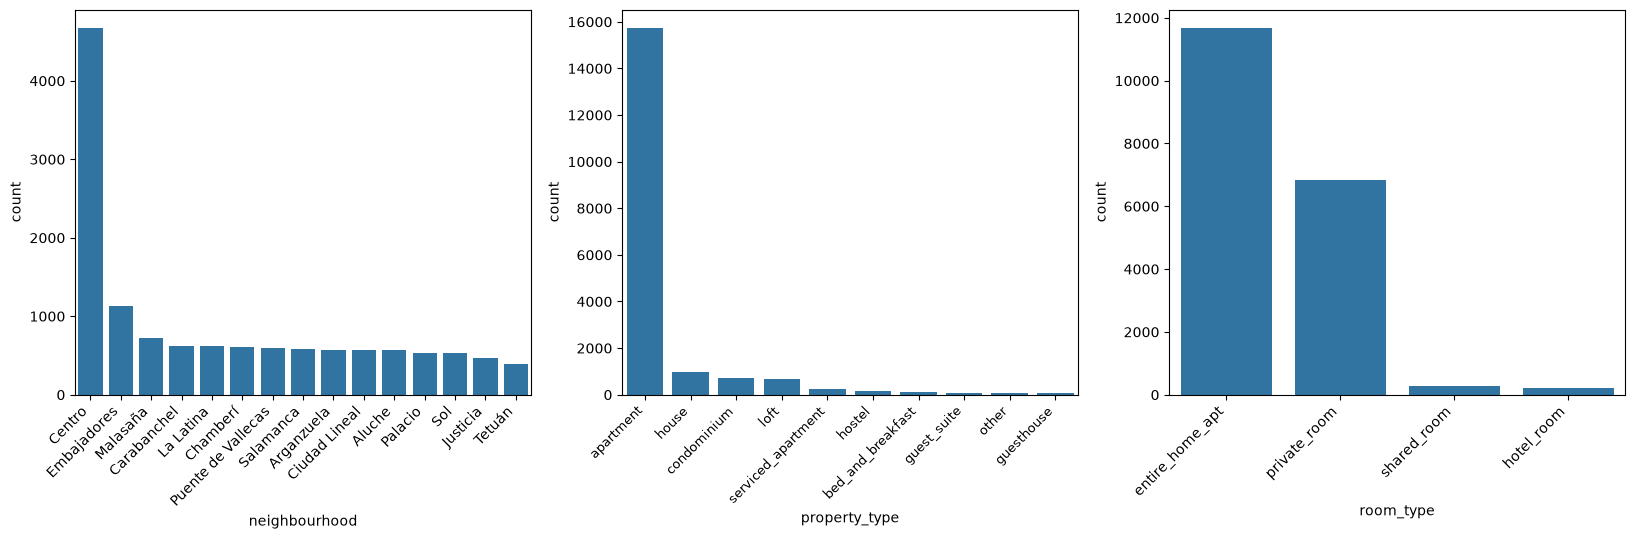

In [11]:
# Plot the distributions of these variables 
fig, ax = plt.subplots(1,3, figsize=(20,5))
# Plot the 15 neighbourhoods with the most listings
top_15_barrios = df_clean.neighbourhood.value_counts().sort_values(ascending=False).head(15).index
sns.countplot(data=df_clean[df_clean.neighbourhood.isin(top_15_barrios)], x='neighbourhood', ax=ax[0], order=top_15_barrios)
ax[0].tick_params(axis='x',rotation=45)
plt.setp(ax[0].get_xticklabels(), ha='right')
# Plot property types
top_10_tipos_propiedad = df_clean.property_type.value_counts().sort_values(ascending=False).head(10).index
sns.countplot(data=df_clean[df_clean.property_type.isin(top_10_tipos_propiedad)], x='property_type', ax=ax[1], order = top_10_tipos_propiedad)
ax[1].tick_params(axis='x',rotation=45, labelsize=9)
plt.setp(ax[1].get_xticklabels(), ha='right')
# Plot room types
sns.countplot(data=df_clean, x='room_type', ax=ax[2], order=df_clean.room_type.value_counts().index)
ax[2].tick_params(axis='x',rotation=45)
plt.setp(ax[2].get_xticklabels(), ha='right')


### Market overview

- The Madrid Airbnb market contains 21,020 listings. Half of the nightly prices fall between €40 and €102; the median is €65. Values range from €1 to €9,999 per night.
- Listings span 66 neighbourhoods. Centro has the largest concentration, nearly 4,000 more listings than Embajadores, the next-largest neighbourhood.
- The source narrative reports 30 property types, with apartments the most common, and four room types, led by entire homes and private rooms.

## 3. Study scope and filters

The client wants recommendations for improving the property offering, reviewing nightly prices, and identifying characteristics associated with lower prices.

The study group contains entire-home apartments with one to three bedrooms and a kitchen. It also retains the previously applied price limit of €200 per night. The following cells apply these conditions and check the resulting subset.

In [12]:
# What values occur in the amenities_kitchen variable?
df_clean.amenities_kitchen.unique()

array([1, 0])

In [13]:
condiciones = (df_clean['property_type'] =='apartment') & (df_clean['room_type'] == 'entire_home_apt') & (df_clean['bedrooms'] >= 1) & (df_clean['bedrooms'] <= 3) & (df_clean['amenities_kitchen'] == 1)

In [14]:
df_study_set = df_clean[condiciones]

In [15]:
# Check the filtered dataset
print(f'Property types: {df_study_set.property_type.unique()}')
print(f'Room types: {df_study_set.room_type.unique()}')
print(f'Bedroom counts: {df_study_set.bedrooms.unique()}')
print(f'Kitchen: {df_study_set.amenities_kitchen.unique()}')
print(f'Maximum price: {df_study_set.price.max()}')

Property types: <ArrowStringArray>
['apartment']
Length: 1, dtype: str
Room types: <ArrowStringArray>
['entire_home_apt']
Length: 1, dtype: str
Bedroom counts: [3. 2. 1.]
Kitchen: [1]
Maximum price: 200.0


## 4. Analytical questions

The analysis examines four groups of characteristics using price distributions, group medians, and Spearman correlations where applicable. The hypotheses below guide the comparisons.

### Hypotheses

The analysis examines how property features, guest reviews, host characteristics, and booking conditions relate to listed prices.

### Property features
- Wi-Fi is associated with higher prices (`amenities_wifi_internet`, `price`).
- A television is associated with higher prices (`amenities_tv`, `price`).
- Air conditioning is associated with higher prices (`amenities_air_conditioning`, `price`).
- Heating is associated with higher prices (`amenities_heating`, `price`).

### Guest reviews
- Higher cleanliness scores are associated with higher prices.
- Higher check-in scores are associated with higher prices.
- Higher communication scores are associated with higher prices.

### Host characteristics
- Superhost status is associated with higher prices.
- Faster response time and a higher response rate are associated with higher prices.

### Booking conditions
- Stricter cancellation policies are associated with lower prices.

## 5. Comparisons by listing characteristic

### Property amenities

WI-FI AND PRICE:

347 listings without Wi-Fi and 8680 listings with Wi-Fi
Median without Wi-Fi: 70.0
Median with Wi-Fi: 80.0
Difference: 10.0 . higher median by 14.29%
--------------------------------------------------
TV AND PRICE:

605 listings without a TV and 8422 listings with a TV
Median without TV: 69.0
Median with TV: 80.0
Difference: 11.0 . higher median by 15.94%
--------------------------------------------------
AIR CONDITIONING AND PRICE:

1819 listings without air conditioning and 7208 listings with air conditioning
Median without air conditioning: 70.0
Median with air conditioning: 80.0
Difference: 10.0 . higher median by 14.29%
--------------------------------------------------
HEATING AND PRICE:

460 listings without heating; 8567 listings with heating
Median without heating: 70.0
Median with heating: 80.0
Difference: 10.0 . higher median by 14.29%


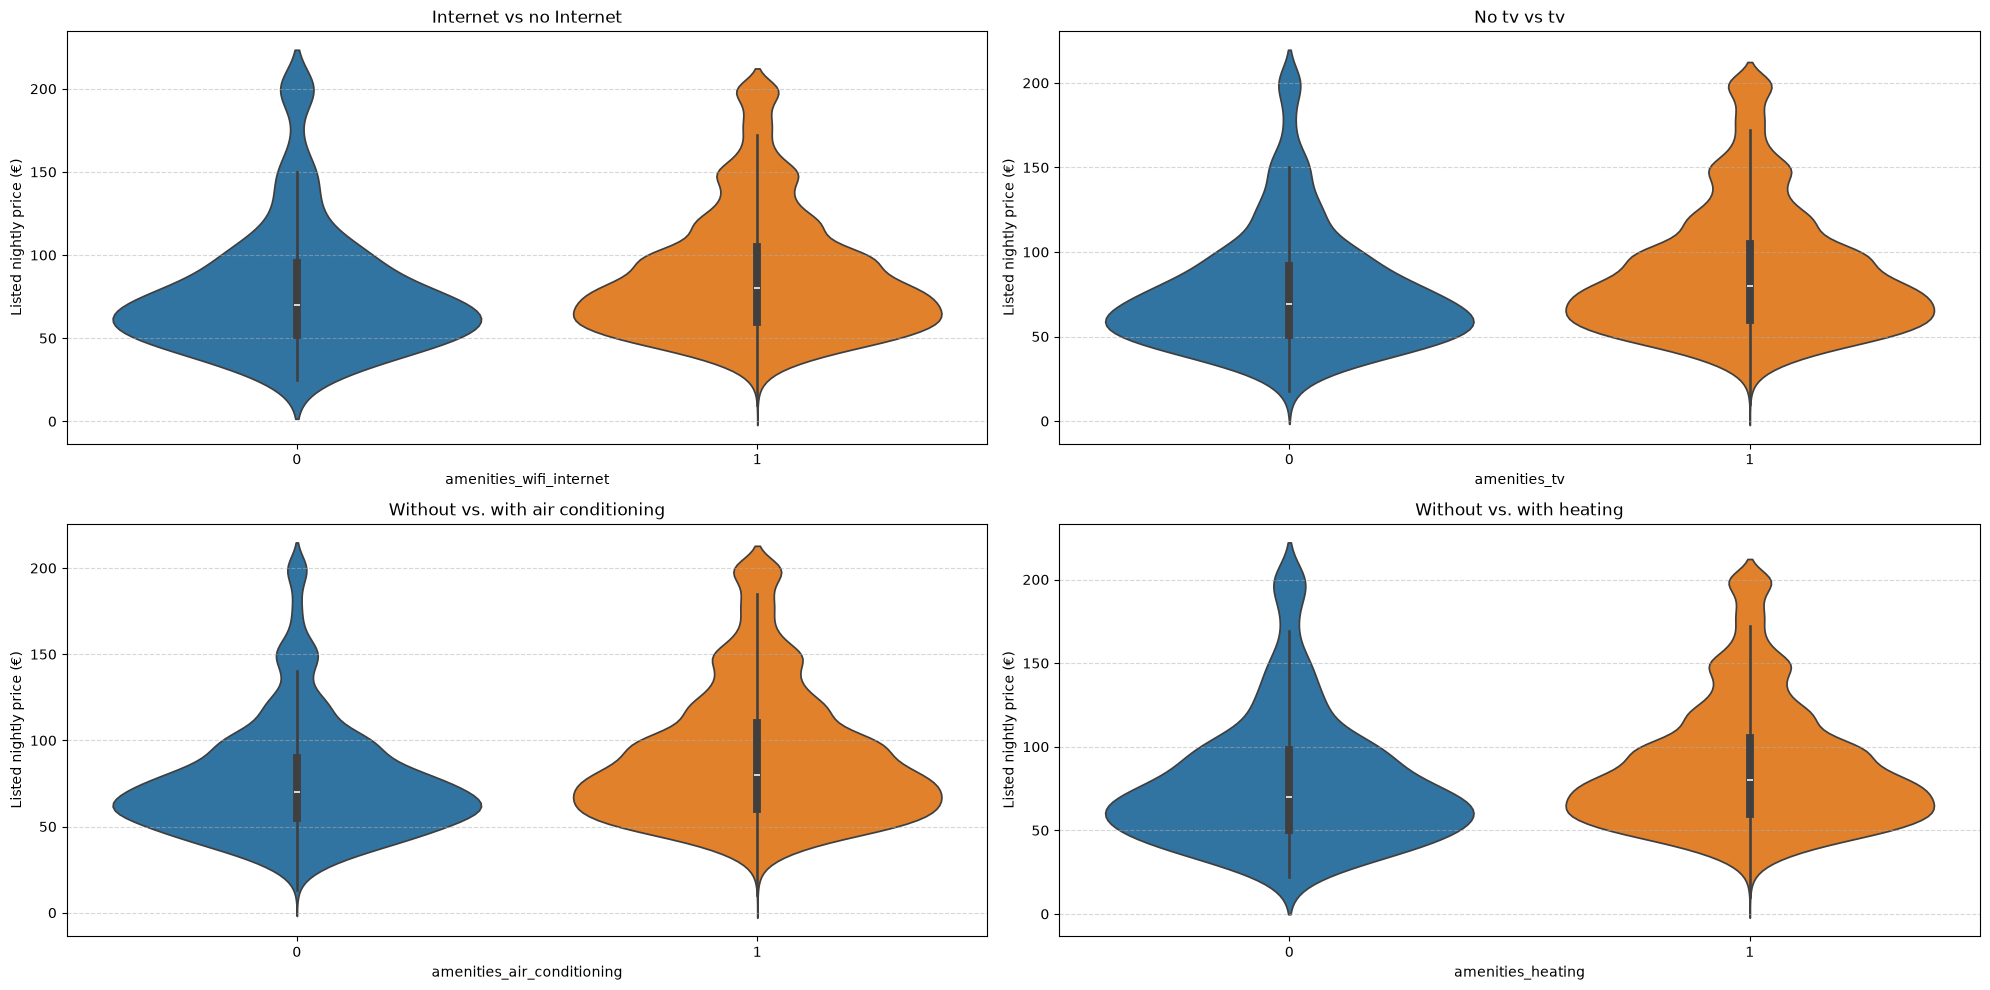

In [16]:
fig, ax = plt.subplots(2,2, figsize=(20, 10))

# Wi-Fi comparison
sns.violinplot(
    data=df_study_set,
    x='amenities_wifi_internet',
    y='price',
    hue='amenities_wifi_internet',
    legend=False,
    ax=ax[0,0]
)
ax[0,0].set_title('Internet vs no Internet')
ax[0,0].grid(visible=True, axis='y', linestyle='--', alpha=0.5)


# Television comparison
sns.violinplot(
    data=df_study_set,
    x='amenities_tv',
    y='price',
    hue='amenities_tv',
    legend=False,
    ax=ax[0,1]
)
ax[0,1].set_title('No tv vs tv')
ax[0,1].grid(visible=True, axis='y', linestyle='--', alpha=0.5)

# Air conditioning comparison
sns.violinplot(
    data=df_study_set,
    x='amenities_air_conditioning',
    y='price',
    hue='amenities_air_conditioning',
    legend=False,
    ax=ax[1,0]
)
ax[1,0].set_title('Without vs. with air conditioning')
ax[1,0].grid(visible=True, axis='y', linestyle='--', alpha=0.5)

# No heating vs. heating
sns.violinplot(
    data=df_study_set,
    x='amenities_heating',
    y='price',
    hue='amenities_heating',
    legend=False,
    ax=ax[1,1]
)
ax[1,1].set_title('Without vs. with heating')
ax[1,1].grid(visible=True, axis='y', linestyle='--', alpha=0.5)

# Calculate medians, differences, and category counts

# Wi-Fi vs. price
internet_vs_precio = df_study_set.groupby('amenities_wifi_internet').price.median()
internet_vs_precio_counts = df_study_set.groupby('amenities_wifi_internet').size()
print('WI-FI AND PRICE:\n')
print(f'{internet_vs_precio_counts.iloc[0]} listings without Wi-Fi and {internet_vs_precio_counts.iloc[1]} listings with Wi-Fi')
print(f'Median without Wi-Fi: {internet_vs_precio.iloc[0]}')
print(f'Median with Wi-Fi: {internet_vs_precio.iloc[1]}')
print(f'Difference: {internet_vs_precio.iloc[1] - internet_vs_precio.iloc[0]} . higher median by {((internet_vs_precio.iloc[1]-internet_vs_precio.iloc[0])/(internet_vs_precio.iloc[0]))*100:.2f}%')
print('-'*50)

# TV vs. price

tv_vs_precio = df_study_set.groupby('amenities_tv').price.median()
tv_vs_precio_counts = df_study_set.groupby('amenities_tv').size()
print('TV AND PRICE:\n')
print(f'{tv_vs_precio_counts.iloc[0]} listings without a TV and {tv_vs_precio_counts.iloc[1]} listings with a TV')
print(f'Median without TV: {tv_vs_precio.iloc[0]}')
print(f'Median with TV: {tv_vs_precio.iloc[1]}')
print(f'Difference: {tv_vs_precio.iloc[1] - tv_vs_precio.iloc[0]} . higher median by {((tv_vs_precio.iloc[1]-tv_vs_precio.iloc[0])/(tv_vs_precio.iloc[0]))*100:.2f}%')
print('-'*50)

# Air conditioning vs. price

air_vs_precio = df_study_set.groupby('amenities_air_conditioning').price.median()
air_vs_precio_counts = df_study_set.groupby('amenities_air_conditioning').size()
print('AIR CONDITIONING AND PRICE:\n')
print(f'{air_vs_precio_counts.iloc[0]} listings without air conditioning and {air_vs_precio_counts.iloc[1]} listings with air conditioning')
print(f'Median without air conditioning: {air_vs_precio.iloc[0]}')
print(f'Median with air conditioning: {air_vs_precio.iloc[1]}')
print(f'Difference: {air_vs_precio.iloc[1] - air_vs_precio.iloc[0]} . higher median by {((air_vs_precio.iloc[1]-air_vs_precio.iloc[0])/(air_vs_precio.iloc[0]))*100:.2f}%')
print('-'*50)

# Heating vs. price

heating_vs_precio = df_study_set.groupby('amenities_heating').price.median()
heating_vs_precio_counts = df_study_set.groupby('amenities_heating').size()
print('HEATING AND PRICE:\n')
print(f'{heating_vs_precio_counts.iloc[0]} listings without heating; {heating_vs_precio_counts.iloc[1]} listings with heating')
print(f'Median without heating: {heating_vs_precio.iloc[0]}')
print(f'Median with heating: {heating_vs_precio.iloc[1]}')
print(f'Difference: {heating_vs_precio.iloc[1] - heating_vs_precio.iloc[0]} . higher median by {((heating_vs_precio.iloc[1]-heating_vs_precio.iloc[0])/(heating_vs_precio.iloc[0]))*100:.2f}%')
for panel in ax.flat:
    panel.set_ylabel('Listed nightly price (€)')
plt.tight_layout()


**Wi-Fi and price**

Listings with Wi-Fi have a median listed price of €80, compared with €70 without it (+14.3%). The groups contain 8,680 and 347 listings. This is a descriptive association within the study group. Wi-Fi is an attribute to investigate when comparing properties; installation costs, booking effects, and returns are not measured.

**Television and price**

Listings with a TV have a median listed price of €80, compared with €69 without one (+15.94%). The groups contain 8,422 and 605 listings. This is the largest relative median difference among the four amenities examined. It supports investigating the comparison, rather than estimating the effect of installing a TV.

**Air conditioning and price**

Listings with air conditioning have a median price of €80, compared with €70 without it (+14.29%). The groups contain 7,208 and 1,819 listings. Installation costs and property differences would need consideration before recommending an investment.

**Heating and price**

Listings with heating have a median price of €80, compared with €70 without it (+14.29%). The groups contain 8,567 and 460 listings. These data do not measure guest expectations or the return from adding heating.

### Guest reviews

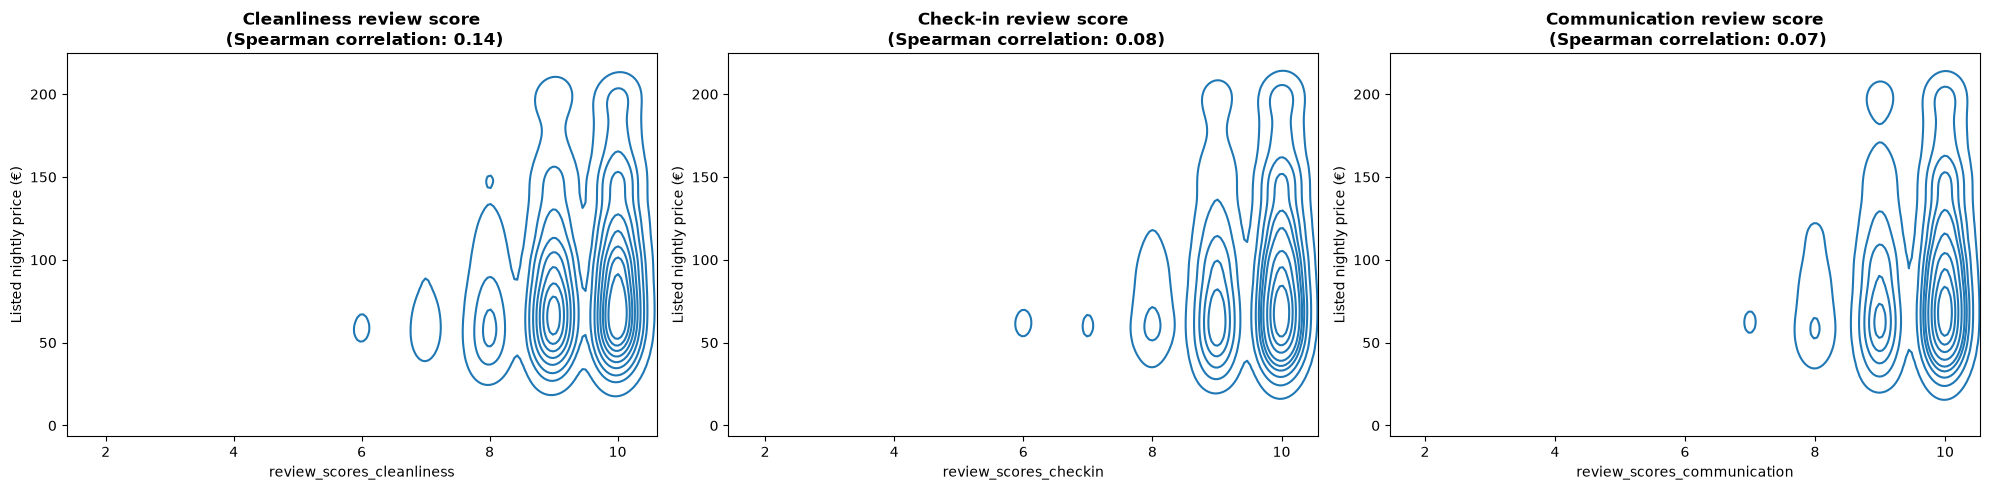

In [17]:
fig, ax = plt.subplots(1,3, figsize=(20, 5))

# Cleanliness review scores

corr_coef = df_study_set.review_scores_cleanliness.corr(df_study_set.price, method='spearman')

sns.kdeplot(
    data=df_study_set,
    x='review_scores_cleanliness',
    y='price',
    legend=False,
    ax=ax[0]
)
ax[0].set_title(f'Cleanliness review score\n (Spearman correlation: {corr_coef:.2f})', fontsize=12, fontweight='bold')


# Check-in review score

corr_coef = df_study_set.review_scores_checkin.corr(df_study_set.price, method='spearman')

sns.kdeplot(
    data=df_study_set,
    x='review_scores_checkin',
    y='price',
    legend=False,
    ax=ax[1]
)
ax[1].set_title(f'Check-in review score\n (Spearman correlation: {corr_coef:.2f})', fontsize=12, fontweight='bold')

# Communication review scores

corr_coef = df_study_set.review_scores_communication.corr(df_study_set.price, method='spearman')

sns.kdeplot(
    data=df_study_set,
    x='review_scores_communication',
    y='price',
    legend=False,
    ax=ax[2]
)
ax[2].set_title(f'Communication review score\n (Spearman correlation: {corr_coef:.2f})', fontsize=12, fontweight='bold');


for panel in ax:
    panel.set_ylabel('Listed nightly price (€)')
plt.tight_layout()


**Cleanliness reviews and price**

Spearman's rank correlation between cleanliness score and price is 0.14. Scores cluster between 8 and 10, and the chart shows a weak relationship with listed price. This does not establish that cleanliness is unimportant for bookings or other outcomes, which are not evaluated here.

**Check-in reviews and price**

Spearman's rank correlation is 0.08. Scores cluster between 8 and 10. The analysis shows a weak relationship with listed price in this subset; it does not estimate the effect of improving check-in.

**Communication reviews and price**

Spearman's rank correlation is 0.07. The analysis reports little relationship between communication ratings and price, consistent with its result for host response rate.

### Host characteristics

SUPERHOST STATUS AND PRICE:

6850 other hosts; 2177 Superhosts
Median for other hosts: 75.5
Median for Superhosts: 85.0
Difference: 9.5 . Higher median by 12.58%
--------------------------------------------------
HOST RESPONSE TIME AND PRICE:

6244 within an hour; 945 within a few hours; 561 within a day; 122 in a few days or more
Median within an hour: 80.0
Median within a few hours: 80.0
Median within a day: 85.0
Median in a few days or more: 77.0
Median difference: within an hour minus a few days or more: 3.0 . Higher median by: 3.90%
Median difference: within a day minus a few days or more: 8.0 . Higher median by: 10.39%


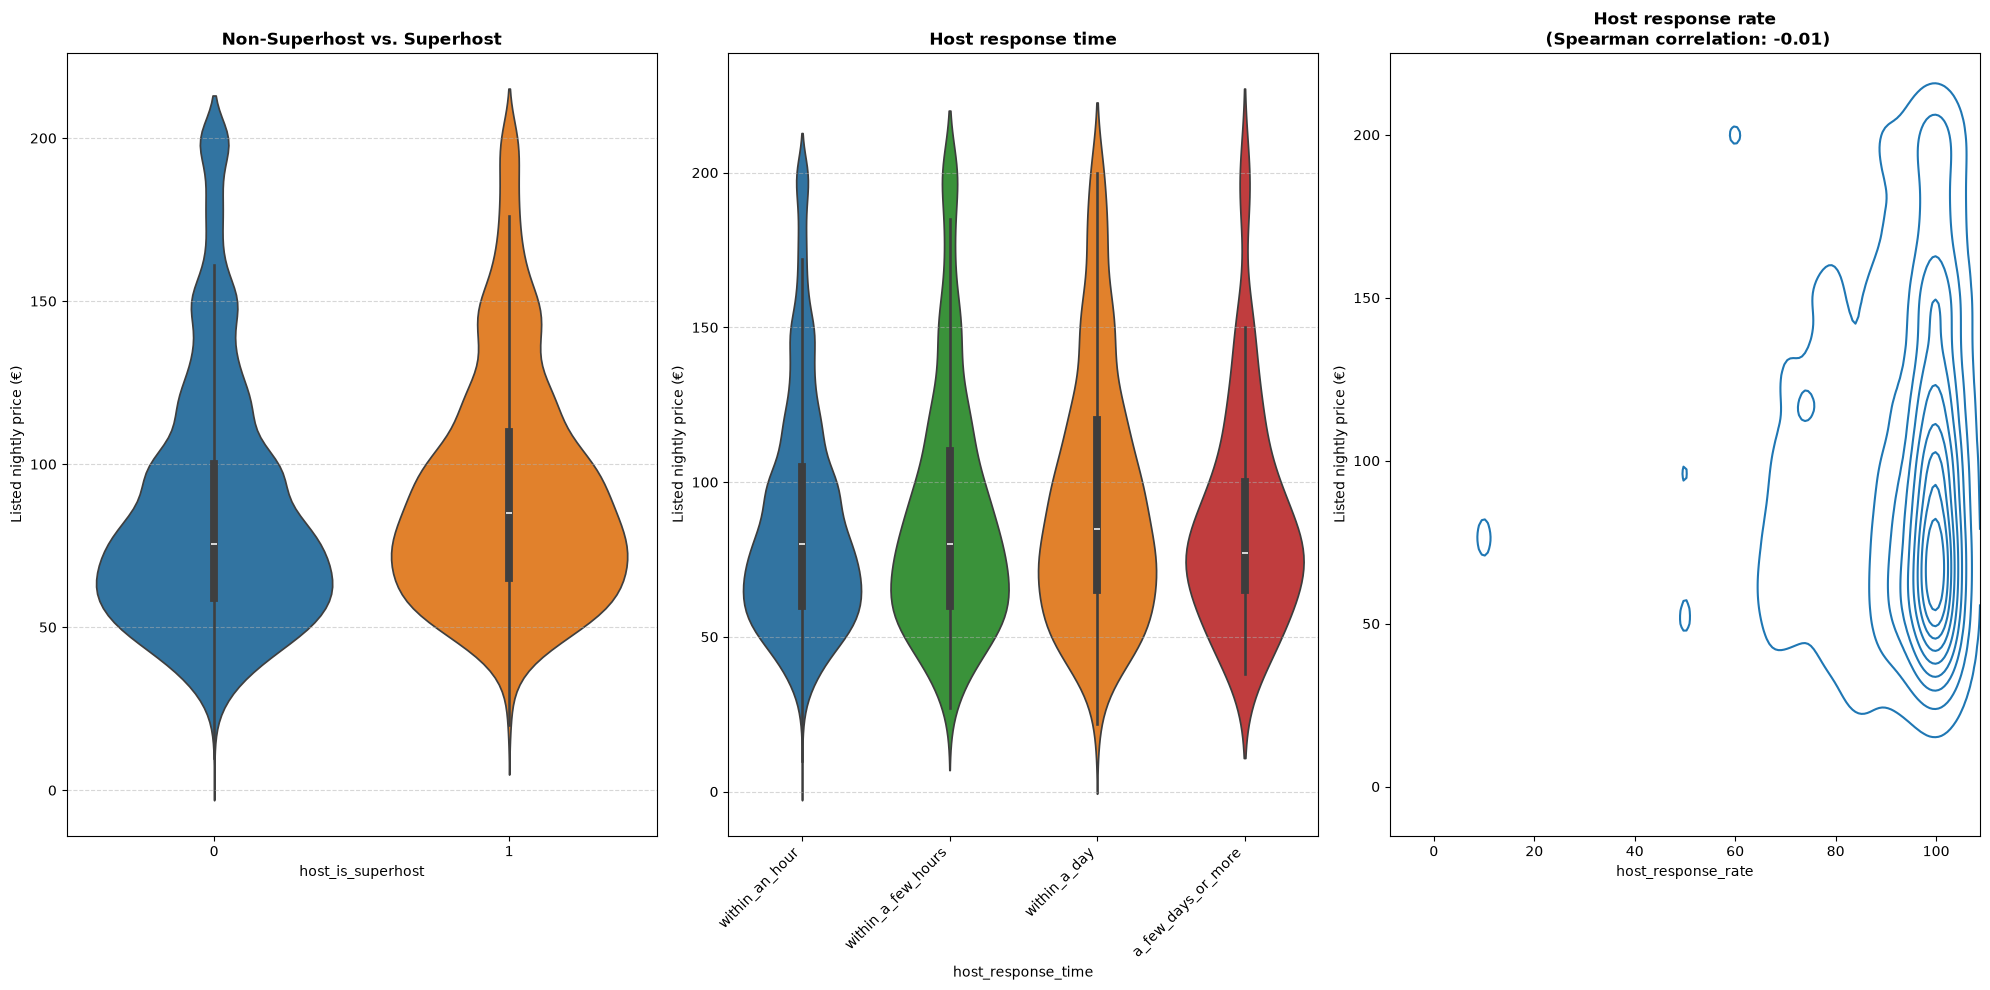

In [18]:
fig, ax = plt.subplots(1,3, figsize=(20, 10))

# Non-Superhost vs. Superhost
sns.violinplot(
    data=df_study_set,
    x='host_is_superhost',
    y='price',
    hue='host_is_superhost',
    legend=False,
    ax=ax[0]
)
ax[0].set_title('Non-Superhost vs. Superhost', fontweight='bold')
ax[0].grid(visible=True, axis='y', linestyle='--', alpha=0.5)


# Host response time
orden = ['within_an_hour', 'within_a_few_hours', 'within_a_day', 'a_few_days_or_more']
sns.violinplot(
    data=df_study_set,
    x='host_response_time',
    y='price',
    hue='host_response_time',
    legend=False,
    ax=ax[1],
    order=orden
)
ax[1].set_title('Host response time', fontweight='bold')
for label in ax[1].get_xticklabels():
    label.set_rotation(45)
    label.set_ha('right')
ax[1].grid(visible=True, axis='y', linestyle='--', alpha=0.5)

# Host response rate

corr_coef = df_study_set.host_response_rate.corr(df_study_set.price, method='spearman')

sns.kdeplot(
    data=df_study_set,
    x='host_response_rate',
    y='price',
    legend=False,
    ax=ax[2]
)
ax[2].set_title(f'Host response rate\n (Spearman correlation: {corr_coef:.2f})', fontsize=12, fontweight='bold')

# Summary statistics: host status vs. Superhost status
superhost_vs_precio = df_study_set.groupby('host_is_superhost').price.median()
superhost_vs_precio_counts = df_study_set.groupby('host_is_superhost').size()
print('SUPERHOST STATUS AND PRICE:\n')
print(f'{superhost_vs_precio_counts.iloc[0]} other hosts; {superhost_vs_precio_counts.iloc[1]} Superhosts')
print(f'Median for other hosts: {superhost_vs_precio.iloc[0]}')
print(f'Median for Superhosts: {superhost_vs_precio.iloc[1]}')
print(f'Difference: {superhost_vs_precio.iloc[1] - superhost_vs_precio.iloc[0]} . Higher median by {((superhost_vs_precio.iloc[1]-superhost_vs_precio.iloc[0])/(superhost_vs_precio.iloc[0]))*100:.2f}%')
print('-'*50)

# Host response time vs. price
tiempo_respuesta_vs_precio = df_study_set.groupby('host_response_time').price.median()
tiempo_respuesta_vs_precio_counts = df_study_set.groupby('host_response_time').size()
print('HOST RESPONSE TIME AND PRICE:\n')
print(f'{tiempo_respuesta_vs_precio_counts.loc['within_an_hour']} within an hour; {tiempo_respuesta_vs_precio_counts.loc['within_a_few_hours']} within a few hours; {tiempo_respuesta_vs_precio_counts.loc['within_a_day']} within a day; {tiempo_respuesta_vs_precio_counts.loc['a_few_days_or_more']} in a few days or more')
print(f'Median within an hour: {tiempo_respuesta_vs_precio.loc['within_an_hour']}')
print(f'Median within a few hours: {tiempo_respuesta_vs_precio.loc['within_a_few_hours']}')
print(f'Median within a day: {tiempo_respuesta_vs_precio.loc['within_a_day']}')
print(f'Median in a few days or more: {tiempo_respuesta_vs_precio.loc['a_few_days_or_more']}')
print(f'Median difference: within an hour minus a few days or more: {tiempo_respuesta_vs_precio.loc['within_an_hour']-tiempo_respuesta_vs_precio.loc['a_few_days_or_more']} . Higher median by: {((tiempo_respuesta_vs_precio.loc['within_an_hour']-tiempo_respuesta_vs_precio.loc['a_few_days_or_more'])/(tiempo_respuesta_vs_precio.loc['a_few_days_or_more']))*100:.2f}%')
print(f'Median difference: within a day minus a few days or more: {tiempo_respuesta_vs_precio.loc['within_a_day']-tiempo_respuesta_vs_precio.loc['a_few_days_or_more']} . Higher median by: {((tiempo_respuesta_vs_precio.loc['within_a_day']-tiempo_respuesta_vs_precio.loc['a_few_days_or_more'])/(tiempo_respuesta_vs_precio.loc['a_few_days_or_more']))*100:.2f}%')



for panel in ax:
    panel.set_ylabel('Listed nightly price (€)')
plt.tight_layout()


**Superhost status and price**

Superhost listings have a median price of €85, compared with €75.50 for other listings (+12.58%). The groups contain 2,177 Superhost listings and 6,850 other listings. The analysis identifies an association with higher prices and identifies Superhost status as an attribute to investigate. It does not estimate the effect or cost of becoming a Superhost.

**Host response time and price**

Listings whose hosts respond within an hour have a median price of €80; the `within_a_day` group has a median of €85. The analysis reports only a €3 difference between the fastest and slowest response groups and does not recommend response time as a price lever.

**Host response rate and price**

Spearman's rank correlation is -0.01. Most response rates fall between 90 and 100, leaving little variation. The analysis concludes that response rate does not show a relationship with listed price.

### Booking conditions

CANCELLATION POLICY AND PRICE:

2109 flexible; 3219 moderate; 3579 strict with grace period; 69 super strict 30; 51 super strict 60
Flexible median: 80.0
Moderate median: 80.0
Strict with grace period median: 76.0
Super strict 30 median: 75.0
Super strict 60 median: 52.0
Median difference: flexible minus super strict 60: 28.0 . Flexible-group median above super strict 60 by: 53.85%


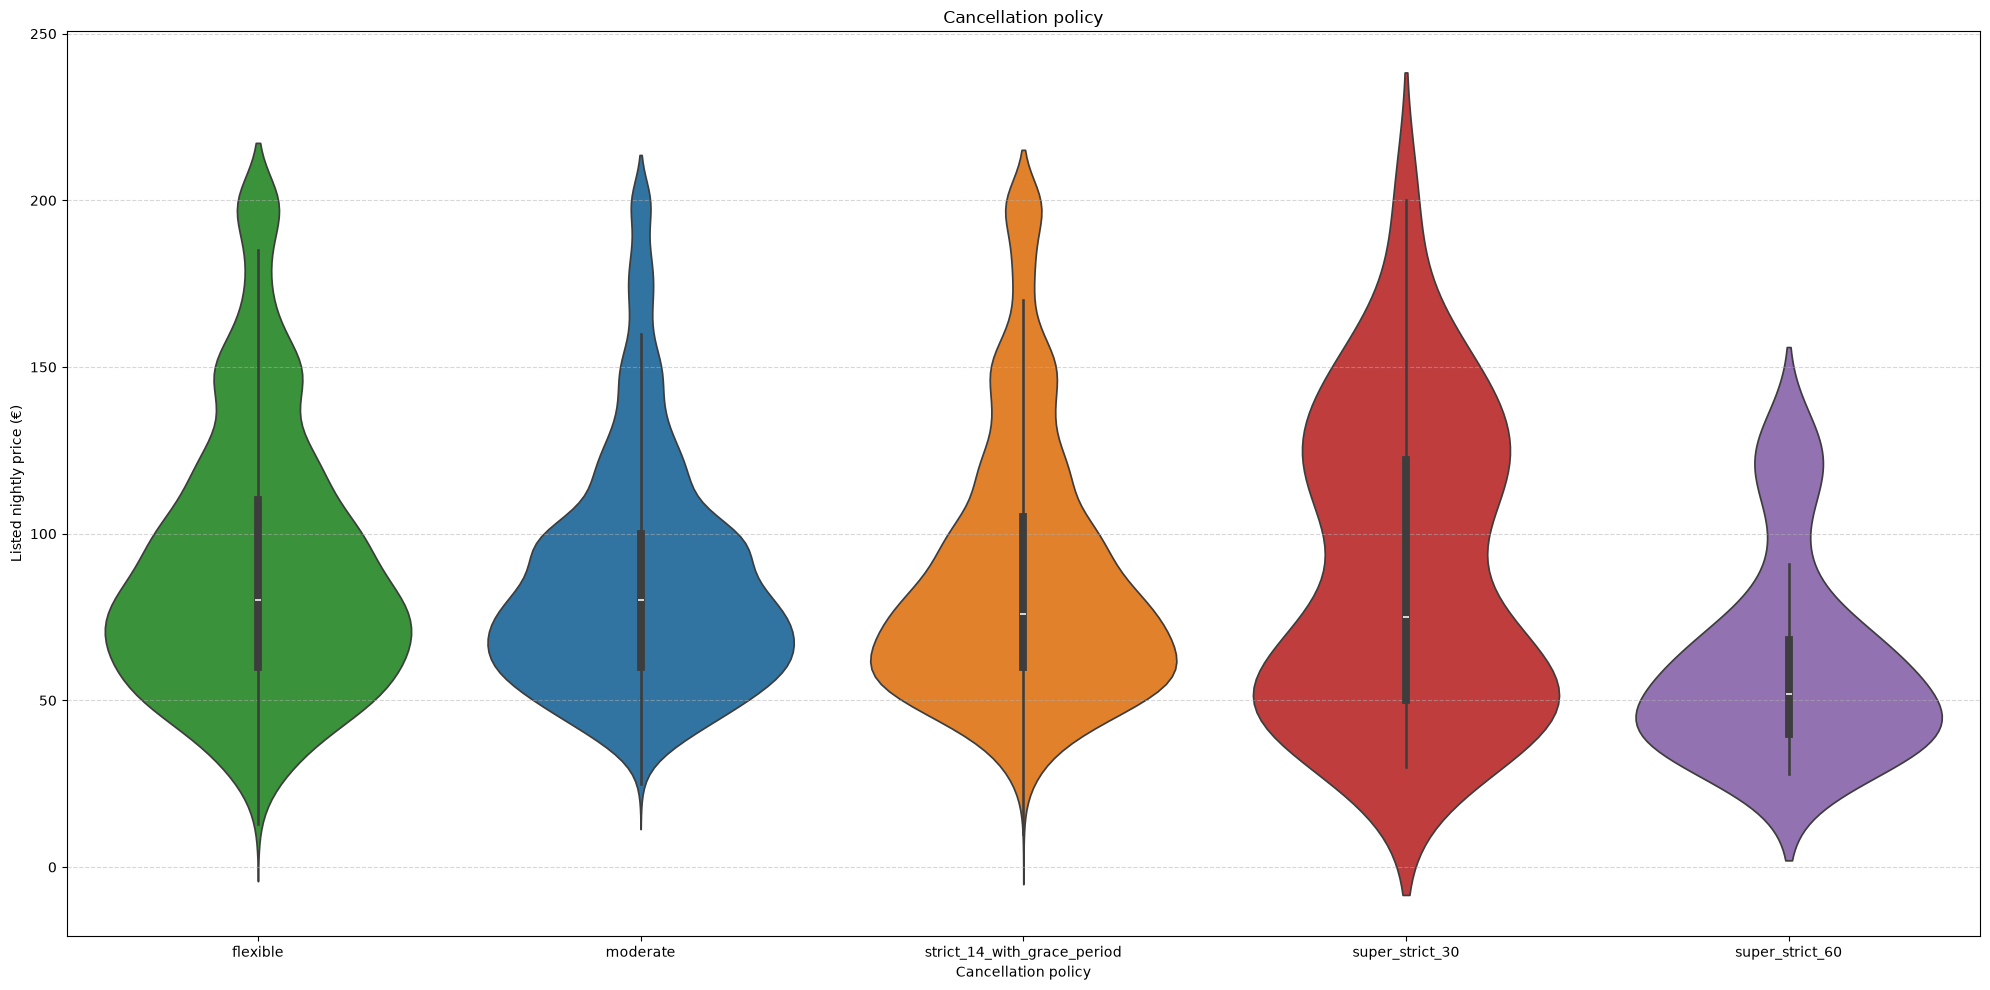

In [19]:
fig, ax = plt.subplots(figsize=(20, 10))
orden=['flexible','moderate','strict_14_with_grace_period','super_strict_30','super_strict_60']

sns.violinplot(
    data=df_study_set,
    x='cancellation_policy',
    y='price',
    hue='cancellation_policy',
    legend=False,
    order=orden
)
ax.set_title('Cancellation policy')
ax.grid(visible=True, axis='y', linestyle='--', alpha=0.5)

# Summary statistics:
politica_cancelacion_vs_precio = df_study_set.groupby('cancellation_policy').price.median()
politica_cancelacion_vs_precio_counts = df_study_set.groupby('cancellation_policy').size()
print('CANCELLATION POLICY AND PRICE:\n')
print(f'{politica_cancelacion_vs_precio_counts.loc['flexible']} flexible; {politica_cancelacion_vs_precio_counts.loc['moderate']} moderate; {politica_cancelacion_vs_precio_counts.loc['strict_14_with_grace_period']} strict with grace period; {politica_cancelacion_vs_precio_counts.loc['super_strict_30']} super strict 30; {politica_cancelacion_vs_precio_counts.loc['super_strict_60']} super strict 60')
print(f'Flexible median: {politica_cancelacion_vs_precio.loc['flexible']}')
print(f'Moderate median: {politica_cancelacion_vs_precio.loc['moderate']}')
print(f'Strict with grace period median: {politica_cancelacion_vs_precio.loc['strict_14_with_grace_period']}')
print(f'Super strict 30 median: {politica_cancelacion_vs_precio.loc['super_strict_30']}')
print(f'Super strict 60 median: {politica_cancelacion_vs_precio.loc['super_strict_60']}')
print(f'Median difference: flexible minus super strict 60: {politica_cancelacion_vs_precio.loc['flexible']-politica_cancelacion_vs_precio.loc['super_strict_60']} . Flexible-group median above super strict 60 by: {((politica_cancelacion_vs_precio.loc['flexible']-politica_cancelacion_vs_precio.loc['super_strict_60'])/(politica_cancelacion_vs_precio.loc['super_strict_60']))*100:.2f}%')

ax.set_xlabel('Cancellation policy')
ax.set_ylabel('Listed nightly price (€)')
plt.tight_layout()


**Cancellation policy and price**

Median price falls from €80 for a flexible policy to €52 for `super_strict_60`: €28 lower, or **35% below the flexible-group median**. Equivalently, €80 is 53.85% above €52; the denominator determines the direction of the percentage comparison. The strictest groups are small (69 and 51 listings). These descriptive differences require further investigation before recommending a policy change.

## 6. Conclusions

Amenity groups and Superhost status show differences in median listed prices. Host response behaviour and review scores show weak or near-zero relationships with price.

The practical next step for a property owner is to investigate comparable listings and the costs of potential improvements, using these attributes as starting points. The analysis does not justify a predicted price increase, investment return, or change in cancellation policy. It retains the original descriptive comparisons and introduces no new pricing method.

## 7. Data limitations

- The analysis uses listed nightly prices. It does not evaluate realized booking revenue or the effect of changing a listing's price.
- Results apply to the selected apartment group and price range, rather than to every property listed in Madrid.
- The comparisons examine one characteristic at a time. The notebook does not fit a multivariable pricing model.
- Some booking-condition groups are small, as discussed in the cancellation-policy section.
- The original dataset source, collection date, and license still need to be documented.

## Project background

Adapted from the original Nuclio Digital School statistical-thinking project. The supplied case and original analysis are retained; the [translated brief](docs/airbnb_project_brief.md) provides the academic context.